# Block Duplication Test — Figure 15

Run the cells in order from a **fresh kernel**. This standalone notebook uses only the shipped `github` directory: CICIoT22 data, the Python model converter, and this notebook. Dependencies: NumPy, pandas, Matplotlib, scikit-learn, and **scikit-learn-intelex** (`sklearnex`). Enable the Intel patch before importing scikit-learn to reproduce RF training.

The notebook independently searches every combination in these declared ranges:

| Parameter | DT | RF |
|---|---|---|
| Selected features | 5–21, step 2 | 3–9, step 2 |
| Maximum depth | 3–21, step 2 | 5–21, step 2 |
| Number of trees | 1 | 2–4, step 1 |
| Maximum leaves per tree | 128, 256, 512, 1024, unlimited | Same |
| Available lanes | 1–7 | 1–7 |
| Available ML blocks | 1–6 | 1–6 |

This gives **450 DT + 540 RF = 990 configurations**, or **41,580 model/resource cases** before target evaluation and pruning. Both SRAM and TCAM eligibility are determined at runtime. No historical winners, expected F1 values, saved result tables, or prefiltered candidate CSVs determine the search.

The split is unchanged: 11,878 training rows, 2,970 test rows, 45 quantized input features (0–99), and three classes. Feature selection uses training data only, with seed 4567. Test macro-F1 selects the curves, matching the published experiment; these are reproduction results, not an independent model-selection evaluation.

For each model/depth/tree/leaf/seed group, one RFE elimination path supplies all requested feature counts. Each fitted model is reused across resource budgets and targets. A conversion is pruned only if a strictly higher-F1 model of the same type is already feasible for that target at the exact same lane/block budget. Equal-F1 candidates are converted to preserve entry-count tie-breaking.

The current artifact converter determines DT/RF feasibility, entry counts, and duplicated feature slots. Its counts can differ from the historical sweep. All conversion is in memory; no P4 files, BFRT scripts, network calls, or installed models are involved.

NB is freshly trained with the feature counts specified by the **published experiment mapping**: lanes 1–7 use [6, 11, 15, 18, 18, 18, 18] features; blocks 1–6 use [6, 11, 15, 18, 18, 18]. Its macro-F1 values are recomputed from the data. NB's one-copy-per-feature placement is an assumption of that mapping, not fresh converter validation.

Runtime, training summaries, conversion outcomes, and selected configurations are reported below. Plotting cells can be rerun without repeating the search.

## Block and Lane Sweeps

In [1]:
# Shared setup: run once before the sweep.
import sys
import time
import warnings
from copy import copy
from dataclasses import replace
from importlib.metadata import version
from itertools import product
from pathlib import Path

if "sklearn" in sys.modules:
    raise RuntimeError("Restart the kernel: sklearnex must be enabled before scikit-learn imports.")
from sklearnex import patch_sklearn
patch_sklearn()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, f_classif
from sklearn.metrics import accuracy_score, f1_score
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

candidates = [
    candidate for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "artifact_evaluation" / "github")
]
GITHUB_ROOT = next(
    (p.resolve() for p in candidates
     if (p / "utils" / "model_conversion.py").is_file()
     and (p / "datasets" / "ciciot22").is_dir()), None,
)
if GITHUB_ROOT is None:
    raise FileNotFoundError("Run from the standalone github directory, its test directory, or project root.")
sys.path.insert(0, str(GITHUB_ROOT))
from utils import model_conversion as conversion
from utils.constants import RANDOM_SEED

if Path(conversion.__file__).resolve().parent != GITHUB_ROOT / "utils":
    raise ImportError("Another utils package is cached; restart the kernel and run this notebook first.")
print("Package versions:", {p: version(p) for p in (
    "numpy", "pandas", "matplotlib", "scikit-learn", "scikit-learn-intelex",
)})
DATA_DIR = GITHUB_ROOT / "datasets" / "ciciot22"
X_train, X_test = (np.load(DATA_DIR / f"X_{split}.npy").astype(np.float64)
                   for split in ("train", "test"))
y_train_raw, y_test_raw = (np.load(DATA_DIR / f"Y_{split}.npy", allow_pickle=True)
                           for split in ("train", "test"))
assert X_train.ndim == X_test.ndim == 2
assert X_train.shape == (11878, 45) and X_test.shape == (2970, 45)
assert y_train_raw.shape == (len(X_train),) and y_test_raw.shape == (len(X_test),)
for values in (X_train, X_test):
    assert np.isfinite(values).all() and ((values >= 0) & (values <= 99)).all()
    assert np.equal(values, np.floor(values)).all()
encoder = LabelEncoder().fit(y_train_raw)
y_train, y_test = encoder.transform(y_train_raw), encoder.transform(y_test_raw)
assert encoder.classes_.tolist() == ["Idle", "Interactions", "Power"]
display(pd.DataFrame({
    "class": encoder.classes_,
    "train": np.bincount(y_train), "test": np.bincount(y_test),
}))
print(f"Seed: {RANDOM_SEED}; macro-F1 over all three classes; no resplitting or subsampling.")

# Independent Cartesian grids: no historical winners, scores, or target filters.
FEATURE_VALUES = {"dt": tuple(range(5, 22, 2)), "rf": tuple(range(3, 10, 2))}
DEPTH_VALUES = {"dt": tuple(range(3, 22, 2)), "rf": tuple(range(5, 22, 2))}
TREE_VALUES = {"dt": (1,), "rf": (2, 3, 4)}
LEAF_LIMITS = (128, 256, 512, 1024, None)
CONFIG_COLUMNS = ["model", "features", "depth", "trees", "max_leaves", "targets"]
CONFIGURATIONS = [
    (model, features, depth, trees, leaves, ("SRAM", "TCAM"))
    for model in ("dt", "rf")
    for features, depth, trees, leaves in product(
        FEATURE_VALUES[model], DEPTH_VALUES[model], TREE_VALUES[model], LEAF_LIMITS,
    )
]
grid_counts = {model: sum(cfg[0] == model for cfg in CONFIGURATIONS) for model in ("dt", "rf")}
assert grid_counts == {"dt": 450, "rf": 540}
assert len(set(CONFIGURATIONS)) == len(CONFIGURATIONS) == 990
print("Configurations:", grid_counts, "; both targets are evaluated at runtime.")
LANES, BLOCKS = range(1, 8), range(1, 7)
RESOURCE_POINTS = list(product(reversed(LANES), reversed(BLOCKS)))


def make_estimator(cfg):
    options = dict(max_depth=cfg["depth"], max_leaf_nodes=cfg["max_leaves"],
                   random_state=RANDOM_SEED, min_samples_leaf=1)
    if cfg["model"] == "dt":
        return DecisionTreeClassifier(**options)
    return RandomForestClassifier(n_estimators=cfg["trees"], criterion="gini",
                                  max_features="sqrt", n_jobs=1, **options)


def train_candidates(configurations):
    trained, path_cache = [], {}
    for order, values in enumerate(configurations):
        cfg = dict(zip(CONFIG_COLUMNS, values))
        key = (cfg["model"], cfg["depth"], cfg["trees"], cfg["max_leaves"], RANDOM_SEED)
        minimum = min(FEATURE_VALUES[cfg["model"]])
        if key not in path_cache:
            path_cache[key] = RFE(
                make_estimator(cfg), n_features_to_select=minimum, step=1,
            ).fit(X_train, y_train)
        path = path_cache[key]
        # RFE removes one feature per step. Runs with the same estimator/seed
        # share the same elimination prefix, regardless of their stopping count.
        selector = copy(path)
        selector.n_features_to_select = cfg["features"]
        selector.n_features_ = cfg["features"]
        selector.support_ = path.ranking_ <= cfg["features"] - minimum + 1
        selector.ranking_ = np.maximum(1, path.ranking_ - cfg["features"] + minimum)
        assert selector.support_.sum() == cfg["features"]
        estimator = (
            path.estimator_ if cfg["features"] == minimum
            else make_estimator(cfg).fit(selector.transform(X_train), y_train)
        )
        selector.estimator_ = estimator
        predictions = estimator.predict(selector.transform(X_test))
        score = f1_score(y_test, predictions, average="macro", labels=range(3), zero_division=0)
        trained.append(dict(cfg, order=order, selector=selector, estimator=estimator,
                            f1_raw=score, f1=round(score, 6),
                            accuracy=accuracy_score(y_test, predictions)))
        if order == 0 or (order + 1) % 25 == 0 or order + 1 == len(configurations):
            print(f"Trained {order + 1}/{len(configurations)} configurations; "
                  f"{len(path_cache)} shared RFE paths; "
                  f"latest: {cfg['model']} features={cfg['features']} "
                  f"depth={cfg['depth']} trees={cfg['trees']} leaves={cfg['max_leaves']}; "
                  f"F1={score:.6f}", flush=True)
    return trained

def convert_point(candidate, system, lanes, blocks):
    # Limit this in-memory analysis only; preserve the physical header layout/capacities.
    limits = replace(
        conversion.TCAM_P4_CONFIG if system == "TCAM" else conversion.SRAM_P4_CONFIG,
        P4_LANE_COUNT=lanes, P4_BLOCK_COUNT=blocks,
    )
    converters = {
        ("dt", "SRAM"): conversion.convert_dt, ("dt", "TCAM"): conversion.convert_tcam_dt,
        ("rf", "SRAM"): conversion.convert_rf, ("rf", "TCAM"): conversion.convert_tcam_rf,
    }
    entries, metadata = converters[candidate["model"], system](
        candidate["estimator"], candidate["selector"], encoder, limits,
    )
    total = int(metadata["total_entries"])
    assert total == len(entries)
    tcam_entries = sum(entry.table.endswith("_aggregate_t") for entry in entries) if system == "TCAM" else 0
    slots = len(metadata["feature_slot_mapping"])
    return dict(entries=total, sram_entries=total - tcam_entries,
                tcam_entries=tcam_entries, used_slots=slots,
                duplication=slots / candidate["features"])


def should_prune(score, incumbent):
    # Equal scores must still be converted for entry-count and duplication tie-breaking.
    return incumbent is not None and score < incumbent


def sweep_candidates(trained, resources=None, prune=True, verbose=True):
    resources = RESOURCE_POINTS if resources is None else list(resources)
    records, best_f1 = [], {}
    for candidate in sorted(trained, key=lambda c: (c["model"], -c["f1"], c["order"])):
        started = time.perf_counter()
        counts = {"ok": 0, "failed": 0, "pruned": 0}
        for lanes, blocks in resources:
            for system in candidate["targets"]:
                row = {k: candidate[k] for k in (
                    "model", "features", "depth", "trees", "order", "f1", "accuracy",
                )}
                row.update(max_leaves=candidate["max_leaves"] or "no_limit",
                           system=system, lanes=lanes, blocks=blocks, reason="")
                key = candidate["model"], system, lanes, blocks
                tick = time.perf_counter()
                if prune and should_prune(candidate["f1"], best_f1.get(key)):
                    row.update(status="pruned", reason="Strictly higher F1 already feasible at this exact budget.")
                else:
                    try:
                        row.update(convert_point(candidate, system, lanes, blocks), status="ok")
                        best_f1[key] = max(candidate["f1"], best_f1.get(key, -np.inf))
                    except ValueError as error:
                        row.update(status="failed", reason=str(error))
                row["seconds"] = time.perf_counter() - tick
                records.append(row)
                counts[row["status"]] += 1
        if verbose:
            print(f"{candidate['model']} features={candidate['features']} depth={candidate['depth']} "
                  f"trees={candidate['trees']} leaves={candidate['max_leaves']}: "
                  f"{counts}; {time.perf_counter() - started:.1f}s", flush=True)
    return pd.DataFrame(records)

Package versions: {'numpy': '2.3.2', 'pandas': '2.3.1', 'matplotlib': '3.10.5', 'scikit-learn': '1.7.1', 'scikit-learn-intelex': '2026.1.0'}


Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


,class,train,test
0,Idle,5939,1485
1,Interactions,2488,622
2,Power,3451,863


Seed: 4567; macro-F1 over all three classes; no resplitting or subsampling.
Configurations: {'dt': 450, 'rf': 540} ; both targets are evaluated at runtime.


In [ ]:
# Train the declared grid from data, then search all lane/block budgets.
run_started = time.perf_counter()
trained = train_candidates(CONFIGURATIONS)
training_seconds = time.perf_counter() - run_started
print(f"DT/RF training completed in {training_seconds:.1f}s.")
print("Training summary (computed scores):")
display(pd.DataFrame([
    {key: candidate[key] for key in ("model", "features", "depth", "trees", "f1", "accuracy")}
    for candidate in trained
]).groupby("model")[["f1", "accuracy"]].agg(["count", "min", "max"]))

# Fresh NB training using the declared experiment mapping, not stored scores.
NB_LANE_FEATURES = [6, 11, 15, 18, 18, 18, 18]
NB_BLOCK_FEATURES = [6, 11, 15, 18, 18, 18]
with warnings.catch_warnings(), np.errstate(invalid="ignore", divide="ignore"):
    warnings.filterwarnings("ignore", message="Features .* are constant.", category=UserWarning)
    scores, _ = f_classif(X_train, y_train)
scores = np.nan_to_num(scores, nan=-np.inf, posinf=np.finfo(float).max, neginf=-np.inf)
print(f"ANOVA: {np.isneginf(scores).sum()} features receive no finite score.")
nb_models, nb_rows = {}, []
for features in sorted(set(NB_LANE_FEATURES + NB_BLOCK_FEATURES)):
    indices = np.sort(np.argsort(scores)[-features:])
    model = CategoricalNB(alpha=0.1, min_categories=100).fit(X_train[:, indices], y_train)
    f1 = f1_score(y_test, model.predict(X_test[:, indices]),
                  average="macro", labels=range(3), zero_division=0)
    nb_models[features] = (model, indices)
    nb_rows.append(dict(features=features, used_slots=len(indices),
                        duplication=len(indices) / features, f1=round(f1, 6)))
nb_results = pd.DataFrame(nb_rows).set_index("features")
display(nb_results)

results = sweep_candidates(trained)
runtime_seconds = time.perf_counter() - run_started
print(f"Training: {training_seconds:.1f}s; total training and sweep: {runtime_seconds:.1f}s")
print(f"{len(CONFIGURATIONS)} trained DT/RF configurations, {len(nb_models)} NB models; "
      f"{len(CONFIGURATIONS) * len(RESOURCE_POINTS)} model/resource cases; "
      f"{len(results)} target checks.")
display(results.groupby(["model", "system", "status"]).size().unstack(fill_value=0))
print("Full per-case failures and pruning reasons remain available in results.")


Trained 1/990 configurations; 1 shared RFE paths; latest: dt features=5 depth=3 trees=1 leaves=128; F1=0.625150
Trained 25/990 configurations; 25 shared RFE paths; latest: dt features=5 depth=11 trees=1 leaves=None; F1=0.781777
Trained 50/990 configurations; 50 shared RFE paths; latest: dt features=5 depth=21 trees=1 leaves=None; F1=0.821411
Trained 75/990 configurations; 50 shared RFE paths; latest: dt features=7 depth=11 trees=1 leaves=None; F1=0.800179
Trained 100/990 configurations; 50 shared RFE paths; latest: dt features=7 depth=21 trees=1 leaves=None; F1=0.831890
Trained 125/990 configurations; 50 shared RFE paths; latest: dt features=9 depth=11 trees=1 leaves=None; F1=0.804152
Trained 150/990 configurations; 50 shared RFE paths; latest: dt features=9 depth=21 trees=1 leaves=None; F1=0.832225
Trained 175/990 configurations; 50 shared RFE paths; latest: dt features=11 depth=11 trees=1 leaves=None; F1=0.805566
Trained 200/990 configurations; 50 shared RFE paths; latest: dt feature

f1                     accuracy                    
      count       min       max    count       min       max
model                                                       
dt      450  0.625150  0.853373      450  0.664646  0.866667
rf      540  0.603165  0.842981      540  0.668013  0.857576

ANOVA: 11 features receive no finite score.


,used_slots,duplication,f1
features,,,
6,6,1.0,0.635724
11,11,1.0,0.664767
15,15,1.0,0.676128
18,18,1.0,0.706818


dt features=15 depth=15 trees=1 leaves=1024: {'ok': 3, 'failed': 81, 'pruned': 0}; 13.2s
dt features=17 depth=15 trees=1 leaves=1024: {'ok': 0, 'failed': 81, 'pruned': 3}; 9.2s
dt features=17 depth=21 trees=1 leaves=1024: {'ok': 0, 'failed': 81, 'pruned': 3}; 2.0s
dt features=15 depth=21 trees=1 leaves=1024: {'ok': 0, 'failed': 81, 'pruned': 3}; 2.2s
dt features=13 depth=21 trees=1 leaves=1024: {'ok': 0, 'failed': 81, 'pruned': 3}; 2.7s
dt features=17 depth=15 trees=1 leaves=None: {'ok': 0, 'failed': 81, 'pruned': 3}; 9.3s
dt features=15 depth=15 trees=1 leaves=None: {'ok': 0, 'failed': 81, 'pruned': 3}; 6.6s
dt features=15 depth=19 trees=1 leaves=None: {'ok': 0, 'failed': 81, 'pruned': 3}; 2.5s
dt features=15 depth=17 trees=1 leaves=1024: {'ok': 0, 'failed': 81, 'pruned': 3}; 5.3s
dt features=13 depth=17 trees=1 leaves=None: {'ok': 2, 'failed': 79, 'pruned': 3}; 5.2s
dt features=11 depth=19 trees=1 leaves=1024: {'ok': 2, 'failed': 77, 'pruned': 5}; 2.7s
dt features=13 depth=19 trees=1

In [3]:
# Select the Pareto frontier and exact-budget winners.
def pair_winners(frame):
    feasible = frame.loc[frame["status"].eq("ok")].copy()
    if feasible.empty:
        raise RuntimeError("No deployable results; inspect results[['model', 'system', 'reason']].")
    return (feasible.sort_values(
        ["model", "system", "lanes", "blocks", "f1", "entries", "order"],
        ascending=[True, True, True, True, False, True, True], kind="stable",
    ).drop_duplicates(["model", "system", "lanes", "blocks"]).reset_index(drop=True))


def select_by_budget(frame, axis):
    other = "blocks" if axis == "lanes" else "lanes"
    return (frame.sort_values(
        ["model", "system", axis, "f1", other, "entries", "order"],
        ascending=[True, True, True, False, True, True, True], kind="stable",
    ).drop_duplicates(["model", "system", axis]).reset_index(drop=True))


def pareto_frontier(frame):
    keep = []
    for _, group in frame.groupby(["model", "system"], sort=False):
        for index, row in group.iterrows():
            dominates = (
                group["lanes"].le(row["lanes"]) & group["blocks"].le(row["blocks"])
                & group["f1"].ge(row["f1"])
                & (group["lanes"].lt(row["lanes"]) | group["blocks"].lt(row["blocks"])
                   | group["f1"].gt(row["f1"]))
            )
            if not dominates.any():
                keep.append(index)
    return frame.loc[keep].reset_index(drop=True)


budget_results = pair_winners(results)
frontier = pareto_frontier(budget_results)
# Global dominance filtering can remove exact-budget points. Select plots from all
# budget winners, not only from the global frontier, to match the original scripts.
lane_points = select_by_budget(budget_results, "lanes")
block_points = select_by_budget(budget_results, "blocks")
summary_columns = [
    "model", "system", "lanes", "blocks", "f1", "features", "depth", "trees",
    "max_leaves", "entries", "used_slots", "duplication",
]
print("Pareto frontier (maximize F1, minimize lanes and blocks):")
display(frontier[summary_columns])
print("Figure 15(a)/(b): exact lane-budget selections")
display(lane_points[summary_columns])
print("Figure 15(c): exact block-budget selections")
display(block_points[summary_columns])


Pareto frontier (maximize F1, minimize lanes and blocks):


,model,system,lanes,blocks,f1,features,depth,trees,max_leaves,entries,used_slots,duplication
0,dt,SRAM,1,5,0.678864,5,5,1,no_limit,772.0,5.0,1.000000
1,dt,SRAM,2,3,0.627511,7,3,1,128,534.0,7.0,1.000000
2,dt,SRAM,2,6,0.738338,7,7,1,no_limit,3841.0,10.0,1.428571
3,dt,SRAM,3,2,0.627511,7,3,1,128,636.0,7.0,1.000000
4,dt,SRAM,3,3,0.714703,15,5,1,no_limit,1453.0,15.0,1.000000
5,dt,SRAM,3,4,0.741689,9,7,1,no_limit,9440.0,13.0,1.444444
6,dt,SRAM,3,6,0.802750,9,11,1,128,14514.0,13.0,1.444444
7,dt,SRAM,4,2,0.678864,5,5,1,no_limit,1346.0,6.0,1.200000
8,dt,SRAM,4,5,0.802750,9,11,1,128,37665.0,15.0,1.666667
9,dt,SRAM,4,6,0.813730,11,15,1,128,20418.0,16.0,1.454545


Figure 15(a)/(b): exact lane-budget selections


,model,system,lanes,blocks,f1,features,depth,trees,max_leaves,entries,used_slots,duplication
0,dt,SRAM,1,5,0.678864,5,5,1,no_limit,772.0,5.0,1.000000
1,dt,SRAM,2,6,0.738338,7,7,1,no_limit,3841.0,10.0,1.428571
2,dt,SRAM,3,6,0.802750,9,11,1,128,14514.0,13.0,1.444444
3,dt,SRAM,4,6,0.813730,11,15,1,128,20418.0,16.0,1.454545
4,dt,SRAM,5,5,0.813730,11,15,1,128,52225.0,17.0,1.545455
5,dt,SRAM,6,6,0.817706,13,11,1,256,46388.0,20.0,1.538462
6,dt,SRAM,7,6,0.828177,21,11,1,256,46175.0,26.0,1.238095
7,dt,TCAM,1,5,0.678864,5,5,1,no_limit,581.0,5.0,1.000000
8,dt,TCAM,2,6,0.781867,5,11,1,512,1979.0,8.0,1.600000
9,dt,TCAM,3,6,0.840943,7,21,1,512,2770.0,12.0,1.714286


Figure 15(c): exact block-budget selections


,model,system,lanes,blocks,f1,features,depth,trees,max_leaves,entries,used_slots,duplication
0,dt,SRAM,7,1,0.627511,7,3,1,128,838.0,7.0,1.000000
1,dt,SRAM,7,2,0.714703,15,5,1,no_limit,2306.0,15.0,1.000000
2,dt,SRAM,7,3,0.741689,9,7,1,no_limit,31116.0,12.0,1.333333
3,dt,SRAM,7,4,0.798631,13,9,1,128,27630.0,16.0,1.230769
4,dt,SRAM,6,5,0.817119,21,13,1,128,31885.0,25.0,1.190476
5,dt,SRAM,7,6,0.828177,21,11,1,256,46175.0,26.0,1.238095
6,dt,TCAM,7,1,0.824507,7,15,1,256,966.0,7.0,1.000000
7,dt,TCAM,7,2,0.840943,7,21,1,512,1426.0,7.0,1.000000
8,dt,TCAM,7,3,0.844656,9,15,1,no_limit,5139.0,16.0,1.777778
9,dt,TCAM,7,4,0.853373,15,15,1,1024,5201.0,27.0,1.800000


## Plotting

In [4]:
# Base plotting: the same row selections feed F1 and duplication plots.
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 22, "pdf.fonttype": 42, "ps.fonttype": 42,
})
CURVES = [
    ("dt", "SRAM", "DT_sram SRAM", "#1F77B4", "o", "-"),
    ("dt", "TCAM", "DT_sram TCAM", "#1F77B4", "^", "--"),
    ("rf", "SRAM", "RF_sram SRAM", "#FF7F0E", "o", "-"),
    ("rf", "TCAM", "RF_sram TCAM", "#FF7F0E", "^", "--"),
]


def plot_panel(points, axis, metric, nb_features, ylabel, figsize):
    budgets = list(LANES if axis == "lanes" else BLOCKS)
    fig, ax = plt.subplots(figsize=figsize)
    all_values = []
    for model, system, label, color, marker, style in CURVES:
        selected = points.loc[points["model"].eq(model) & points["system"].eq(system)]
        values = selected.set_index(axis)[metric].reindex(budgets).to_numpy(dtype=float)
        all_values.extend(values[np.isfinite(values)])
        ax.plot(budgets, values, label=label, color=color, marker=marker,
                linestyle=style, linewidth=2, markersize=7)
    nb_values = [nb_results.loc[k, metric] for k in nb_features]
    all_values.extend(nb_values)
    ax.plot(budgets, nb_values, label="NB", color="#2CA02C", marker="o",
            linestyle="-", linewidth=2, markersize=7)
    ax.set_xlabel("# Lanes" if axis == "lanes" else "# ML blocks")
    ax.set_ylabel(ylabel)
    ax.set_xticks(budgets)
    ax.set_xlim(0.8, budgets[-1] + 0.2)
    if metric == "f1" and axis == "lanes":
        ax.set_ylim(0.55, 0.9)
    else:
        low, high = min(all_values), max(all_values)
        padding = max(0.01 if metric == "f1" else 0.05, (high - low) * 0.15)
        ax.set_ylim(max(0, low - padding), min(1, high + padding) if metric == "f1" else high + padding)
    ax.grid(True, axis="y", alpha=0.3)
    ax.grid(True, axis="x", alpha=0.12)
    ax.spines[["top", "right"]].set_visible(False)
    if metric == "f1" and axis == "lanes":
        ax.legend(frameon=False, fontsize=12, ncol=3, loc="lower left", columnspacing=0.8)
    fig.tight_layout()
    plt.show()
    return fig


### Figure 15(a)

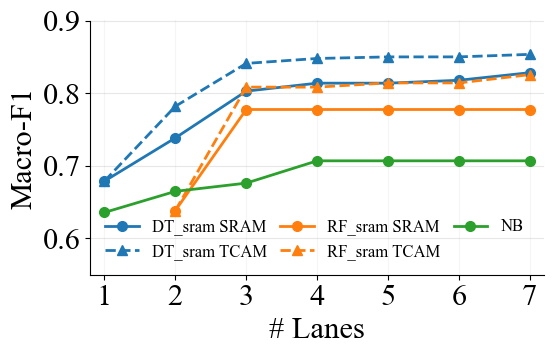

In [5]:
# Plot figure 15(a): lane budget versus macro-F1.
fig15a = plot_panel(lane_points, "lanes", "f1", NB_LANE_FEATURES, "Macro-F1", (6, 4))

### Figure 15(b)

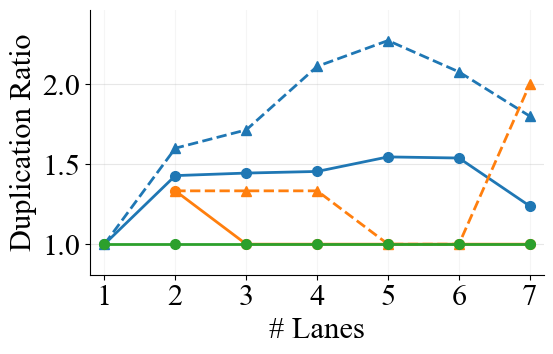

In [6]:
# Plot figure 15(b): occupied feature slots / number of selected features.
fig15b = plot_panel(lane_points, "lanes", "duplication", NB_LANE_FEATURES, "Duplication Ratio", (6, 4))

### Figure 15(c)

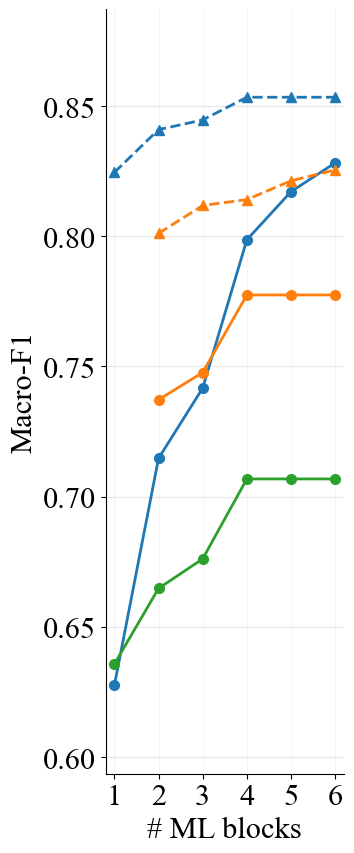

In [7]:
# Plot figure 15(c): ML-block budget versus macro-F1.
fig15c = plot_panel(block_points, "blocks", "f1", NB_BLOCK_FEATURES, "Macro-F1", (4, 9))